In [42]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import smlp

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [13]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset, vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [14]:
# hidden_dim=128
# dropout=0.1
# batch_size=64
# learning_rate=1e-3
# weight_decay=1e-4
# num_epochs=10
# device='cpu'

# metrics_for_all, best_epoch, best_preds = smlp.train_neural_network_model(
#     my_cross_validation_sets[0][0]["training"],  # remember to index datasets by [run][fold]
#     my_cross_validation_sets[0][0]["validation"],  # remember to index datasets by [run][fold]
#     num_classes=1,
#     encoder=bow_encoder, 
#     save_to=f'{results_folder}/tmpmodel',
#     hidden_dim=hidden_dim, 
#     dropout=dropout, 
#     batch_size=batch_size, 
#     learning_rate=learning_rate,
#     weight_decay=weight_decay, 
#     num_epochs=num_epochs,
#     device='cpu'
# )

In [15]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_bow-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/singleMLP_bow-enc/seed-{seed}"
    my_classifiers['singleMLP_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='smlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim, 
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.747 seconds
Dataloader done! Time taken: 0.060 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6856 | train acc: 0.5729 | val loss: 0.6695 | val acc: 0.5915
Epoch 02 | train loss: 0.6683 | train acc: 0.5930 | val loss: 0.6677 | val acc: 0.5896
Epoch 03 | train loss: 0.6624 | train acc: 0.6002 | val loss: 0.6675 | val acc: 0.5940
Epoch 04 | train loss: 0.6587 | train acc: 0.6043 | val loss: 0.6601 | val acc: 0.5996
Epoch 05 | train loss: 0.6568 | train acc: 0.6078 | val loss: 0.6608 | val acc: 0.5967
Epoch 06 | train loss: 0.6543 | train acc: 0.6092 | val loss: 0.6559 | val acc: 0.6051
Epoch 07 | train loss: 0.6527 | train acc: 0.6116 | val loss: 0.6583 | val acc: 0.6007
Epoch 08 | train loss: 0.6512 | train acc: 0.6146 | val loss: 0.6571 | val acc: 0.6062
Epoch 09 | train loss: 0.6492 | train acc: 0.6151 | val loss: 0.6579 | val acc: 0.6010
Epoch 10 | train loss: 0.6479 | train acc: 0.6168 | val loss: 0.6551 | val acc: 0.6050
Training done! Time taken: 89.355 seconds
Transforming documents...
Document transformation done! Time taken: 3.773 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6842 | train acc: 0.5746 | val loss: 0.6836 | val acc: 0.5681
Epoch 02 | train loss: 0.6668 | train acc: 0.5949 | val loss: 0.6683 | val acc: 0.5890
Epoch 03 | train loss: 0.6614 | train acc: 0.6001 | val loss: 0.6694 | val acc: 0.5932
Epoch 04 | train loss: 0.6583 | train acc: 0.6043 | val loss: 0.6644 | val acc: 0.5978
Epoch 05 | train loss: 0.6562 | train acc: 0.6075 | val loss: 0.6628 | val acc: 0.6013
Epoch 06 | train loss: 0.6531 | train acc: 0.6099 | val loss: 0.6617 | val acc: 0.6014
Epoch 07 | train loss: 0.6514 | train acc: 0.6122 | val loss: 0.6639 | val acc: 0.5964
Epoch 08 | train loss: 0.6493 | train acc: 0.6141 | val loss: 0.6602 | val acc: 0.5985
Epoch 09 | train loss: 0.6476 | train acc: 0.6177 | val loss: 0.6596 | val acc: 0.6024
Epoch 10 | train loss: 0.6458 | train acc: 0.6186 | val loss: 0.6589 | val acc: 0.6000
Training done! Time taken: 91.150 seconds
Transforming documents...
Document transformation done! Time taken: 3.699 seconds
Datalo

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6911 | train acc: 0.5630 | val loss: 0.6652 | val acc: 0.5997
Epoch 02 | train loss: 0.6717 | train acc: 0.5872 | val loss: 0.6609 | val acc: 0.6048
Epoch 03 | train loss: 0.6660 | train acc: 0.5949 | val loss: 0.6579 | val acc: 0.6147
Epoch 04 | train loss: 0.6629 | train acc: 0.5968 | val loss: 0.6593 | val acc: 0.6014
Epoch 05 | train loss: 0.6599 | train acc: 0.6017 | val loss: 0.6557 | val acc: 0.6112
Epoch 06 | train loss: 0.6579 | train acc: 0.6043 | val loss: 0.6546 | val acc: 0.6092
Epoch 07 | train loss: 0.6559 | train acc: 0.6056 | val loss: 0.6506 | val acc: 0.6174
Epoch 08 | train loss: 0.6541 | train acc: 0.6086 | val loss: 0.6502 | val acc: 0.6135
Epoch 09 | train loss: 0.6526 | train acc: 0.6093 | val loss: 0.6495 | val acc: 0.6153
Epoch 10 | train loss: 0.6518 | train acc: 0.6103 | val loss: 0.6475 | val acc: 0.6173
Training done! Time taken: 88.353 seconds
Transforming documents...
Document transformation done! Time taken: 3.720 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6901 | train acc: 0.5714 | val loss: 0.6763 | val acc: 0.5793
Epoch 02 | train loss: 0.6703 | train acc: 0.5912 | val loss: 0.6679 | val acc: 0.5845
Epoch 03 | train loss: 0.6644 | train acc: 0.5970 | val loss: 0.6652 | val acc: 0.5912
Epoch 04 | train loss: 0.6614 | train acc: 0.6016 | val loss: 0.6631 | val acc: 0.5966
Epoch 05 | train loss: 0.6594 | train acc: 0.6045 | val loss: 0.6602 | val acc: 0.6023
Epoch 06 | train loss: 0.6569 | train acc: 0.6085 | val loss: 0.6615 | val acc: 0.5988
Epoch 07 | train loss: 0.6550 | train acc: 0.6107 | val loss: 0.6601 | val acc: 0.6035
Epoch 08 | train loss: 0.6538 | train acc: 0.6123 | val loss: 0.6579 | val acc: 0.6050
Epoch 09 | train loss: 0.6518 | train acc: 0.6142 | val loss: 0.6614 | val acc: 0.6069
Epoch 10 | train loss: 0.6502 | train acc: 0.6155 | val loss: 0.6558 | val acc: 0.6087
Training done! Time taken: 89.512 seconds


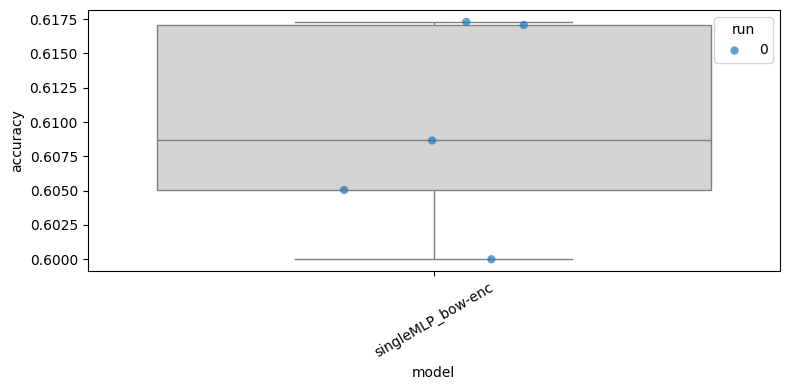

In [16]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [43]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bow_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = smlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/singleMLP_bow-enc/seed-{seed}/fold-{fold}/model"
        model = smlp.load(model_folder)

        smlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = smlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6783207731509427, 'accuracy': 0.5630733944954128}
              precision    recall  f1-score   support

           0       0.58      0.38      0.46       428
           1       0.55      0.74      0.63       444

    accuracy                           0.56       872
   macro avg       0.57      0.56      0.55       872
weighted avg       0.57      0.56      0.55       872

{'loss': 0.678564709260923, 'accuracy': 0.5802752293577982}
              precision    recall  f1-score   support

           0       0.58      0.50      0.54       428
           1       0.58      0.65      0.61       444

    accuracy                           0.58       872
   macro avg       0.58      0.58      0.58       872
weighted avg       0.58      0.58      0.58       872

{'loss': 0.6764341133450149, 'accuracy': 0.5722477064220184}
              precision    recall  f1-score   support

           0       0.59      0.44      0.50       428
           1       0.56      0.70      0.63       444

